In [2]:
%matplotlib inline

import random
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import normalize
import numpy as np


In [3]:
data = pd.read_csv('monthly-milk-production.csv', sep = ';')
data.milk = data.milk.apply(pd.to_numeric)
data['month_dt'] = pd.to_datetime(data.month, dayfirst = True)
data['milk_daily'] = np.array([float(m) for m in data['milk']])/[m.days_in_month for m in data['month_dt']]

data.head(6)

,month,milk,month_dt,milk_daily
0,01.01.1962,589,1962-01-01,19.000000
1,01.02.1962,561,1962-02-01,20.035714
2,01.03.1962,640,1962-03-01,20.645161
3,01.04.1962,656,1962-04-01,21.866667
4,01.05.1962,727,1962-05-01,23.451613
5,01.06.1962,697,1962-06-01,23.233333


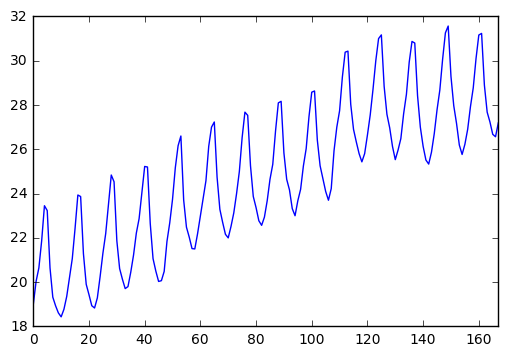

In [4]:
# 6.
pl = data['milk_daily'].plot()

In [10]:
# 7.
import statsmodels.api as sm
adf_pvalue = sm.tsa.stattools.adfuller(data['milk_daily'].values)[0]
D = [(0, adf_pvalue)]
d = [(0, adf_pvalue)]

data_len = len(data['milk_daily'])
for ndx in range(1, 12): 
    diff = data['milk_daily'] - data['milk_daily'].shift(ndx * 12)
    diff.dropna(inplace = True)
    # print(len(diff.values), len(data['milk_daily'].values))
    adf = sm.tsa.stattools.adfuller(diff.values)
    # print(adf)
    D.append((ndx, adf[1]))
    
for ndx in range(1, data_len // 2): 
    diff = data['milk_daily'] - data['milk_daily'].shift(ndx)
    diff.dropna(inplace = True)
    adf = sm.tsa.stattools.adfuller(diff.values)
    d.append((ndx, adf[1]))
    

print('D', D[:5])
print('d', d[:5])

print('D min', sorted(D, key = lambda _: _[1])[:5])
print('d min', sorted(d, key = lambda _: _[1])[:5])

# Ряд становится стационарным после однократного дифференцирования - NO
# Ряд становится стационарным после сезонного дифференцирования - NO
# Ряд становится стационарным после двух последовательных дифференцирований — сезонного и обычного - YES !!!!

diff = data['milk_daily'] - data['milk_daily'].shift(12)
diff.dropna(inplace = True)

print(len(diff.values))

diff = diff - diff.shift(1)
diff.dropna(inplace = True)

print(len(diff.values))
adf = sm.tsa.stattools.adfuller(diff.values)
print(adf)

D [(0, -1.1798216373266039), (1, 0.221276726588304), (2, 0.27744009334585007), (3, 0.43203572269564383), (4, 0.49481061502771218)]
d [(0, -1.1798216373266039), (1, 0.064300546541742651), (2, 0.064014584113565989), (3, 0.064184797720949496), (4, 0.060722280541305816)]
D min [(0, -1.1798216373266039), (5, 0.20690026051593685), (1, 0.221276726588304), (11, 0.24669012073942614), (2, 0.27744009334585007)]
d min [(0, -1.1798216373266039), (9, 0.00028291518586310064), (15, 0.00086858361251423478), (17, 0.0010327775448451028), (11, 0.0011228344511987304)]
156
155
(-5.4813263347969325, 2.2808455518036712e-06, 11, 143, {'10%': -2.5776654080884152, '1%': -3.4769274060112707, '5%': -2.8819726324025625}, -20.905137509892256)


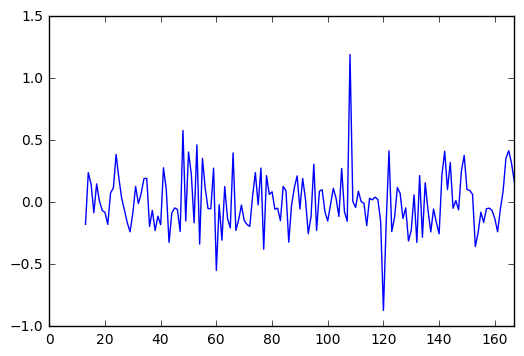

In [12]:
data['milk_shifted'] = diff # - data['milk_daily'].shift(12)
pl = data['milk_shifted'].plot()

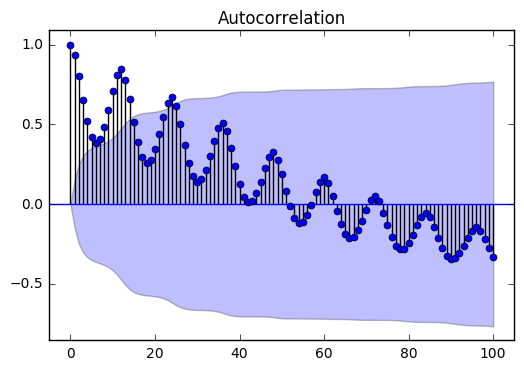

In [13]:
# 8.
import statsmodels.api as sm
pl = sm.graphics.tsa.plot_acf(data['milk_daily'].values.squeeze(), lags=100)


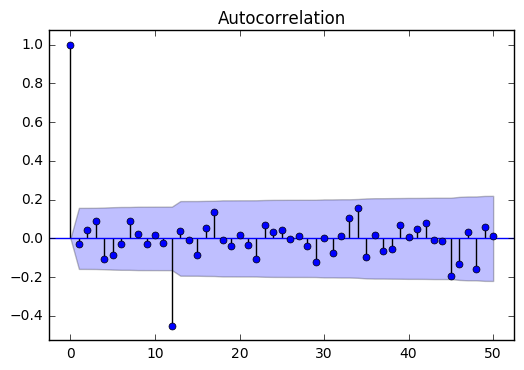

In [16]:
###### import statsmodels.api as sm
plt.figure(figsize = (20,20))
pl = sm.graphics.tsa.plot_acf(data.milk_shifted.dropna().squeeze(), lags=50)
# 8.
# Q = 4 (48) - NO
# Q = 0 - NO
# Q = 1 - YES !!!!

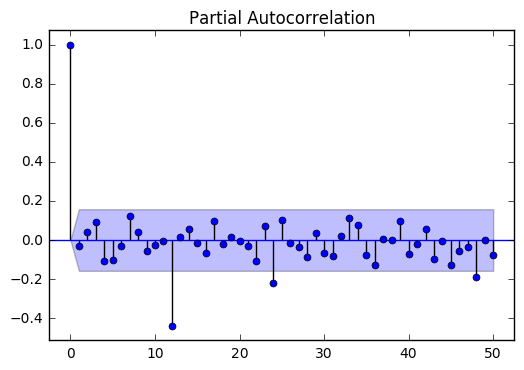

In [26]:
# 9.
import statsmodels.api as sm
p = sm.graphics.tsa.plot_pacf(data.milk_shifted.dropna().squeeze(), lags=50)

# p = 13 - NO
# p = 25 - NO
# p = 12 - NO

# p = 0 - ? 